In [2]:
# Aishi De, 23070521008, Semester 7, Section A

In [ ]:
# WASTELESS - Smart Discounts, Less Waste, A Greener Future.

In [12]:

from IPython.display import display, HTML

display(HTML("""
<div style="
    background: linear-gradient(135deg, #14532d, #16a34a);
    padding: 35px;
    border-radius: 18px;
    text-align: center;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="font-size: 44px; margin: 0;">
        🌱 WasteLess
    </h1>
    <h3 style="font-weight: normal; margin: 15px 0;">
        Smart Discounts, Less Waste, A Greener Future.
    </h3>
    <p style="font-size: 16px; margin-bottom: 0;">
        AI-Powered Market Basket Analysis for Sustainable Retail
    </p>
    <p> - Aishi De </p>
</div>
"""))


In [13]:
%pip install pandas matplotlib mlxtend

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import date, timedelta
from mlxtend.frequent_patterns import apriori, association_rules
from IPython.display import display, Markdown

print("WasteLess system initialized successfully!")


WasteLess system initialized successfully!


In [15]:

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter"],
    ["Milk", "Cereal", "Banana"],
    ["Bread", "Milk", "Butter"],
    ["Yogurt", "Granola", "Banana"],
    ["Yogurt", "Granola"],
    ["Milk", "Bread", "Eggs"],
    ["Coffee", "Cookies", "Milk"],
    ["Coffee", "Cookies"],
    ["Bread", "Butter", "Jam"],
    ["Yogurt", "Banana", "Granola"],
    ["Milk", "Cereal"],
    ["Pasta", "Tomato Sauce", "Cheese"],
    ["Pasta", "Tomato Sauce"],
    ["Bread", "Butter", "Milk"],
    ["Coffee", "Cookies", "Sugar"],
    ["Eggs", "Bread", "Milk"],
    ["Yogurt", "Granola", "Milk"],
    ["Pasta", "Tomato Sauce", "Cheese"],
    ["Banana", "Cereal", "Milk"],
    ["Bread", "Butter", "Jam"],
    ["Coffee", "Cookies"],
    ["Milk", "Bread"],
    ["Yogurt", "Granola"],
    ["Pasta", "Cheese", "Tomato Sauce"]
]

print("Total transactions:", len(transactions))


Total transactions: 25


In [16]:

all_products = sorted(set(
    product
    for transaction in transactions
    for product in transaction
))

basket_df = pd.DataFrame([
    {product: product in transaction for product in all_products}
    for transaction in transactions
])

basket_df = basket_df.astype(bool)

print("Transaction matrix:")
display(basket_df.head(10))


Transaction matrix:


,Banana,Bread,Butter,Cereal,Cheese,Coffee,Cookies,Eggs,Granola,Jam,Milk,Pasta,Sugar,Tomato Sauce,Yogurt
0,False,True,True,False,False,False,False,False,False,False,True,False,False,False,False
1,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False
2,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False
3,False,True,True,False,False,False,False,False,False,False,True,False,False,False,False
4,True,False,False,False,False,False,False,False,True,False,False,False,False,False,True
5,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True
6,False,True,False,False,False,False,False,True,False,False,True,False,False,False,False
7,False,False,False,False,False,True,True,False,False,False,True,False,False,False,False
8,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False
9,False,True,True,False,False,False,False,False,False,True,False,False,False,False,False


In [17]:

frequent_itemsets = apriori(
    basket_df,
    min_support=0.08,
    use_colnames=True
)

frequent_itemsets["Products"] = frequent_itemsets["itemsets"].apply(
    lambda products: ", ".join(sorted(products))
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support", ascending=False
)

print("Frequently purchased product combinations:")
display(frequent_itemsets[["Products", "support"]].head(20))


Frequently purchased product combinations:


,Products,support
10,Milk,0.44
1,Bread,0.36
18,"Bread, Butter",0.24
2,Butter,0.24
21,"Bread, Milk",0.24
29,"Granola, Yogurt",0.20
8,Granola,0.20
13,Yogurt,0.20
12,Tomato Sauce,0.16
30,"Pasta, Tomato Sauce",0.16


In [18]:

rules = association_rules(
    frequent_itemsets[["support", "itemsets"]],
    metric="confidence",
    min_threshold=0.30
)

if not rules.empty:
    rules["Antecedents"] = rules["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    rules["Consequents"] = rules["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )

    rules = rules.sort_values(
        ["lift", "confidence"],
        ascending=False
    )

    display(
        rules[[
            "Antecedents",
            "Consequents",
            "support",
            "confidence",
            "lift"
        ]].round(3).head(20)
    )
else:
    print("No association rules found. Try lowering min_threshold.")


,Antecedents,Consequents,support,confidence,lift
39,"Banana, Milk",Cereal,0.08,1.000,8.333
40,Cereal,"Banana, Milk",0.08,0.667,8.333
6,Tomato Sauce,Pasta,0.16,1.000,6.250
7,Pasta,Tomato Sauce,0.16,1.000,6.250
8,Cookies,Coffee,0.16,1.000,6.250
9,Coffee,Cookies,0.16,1.000,6.250
16,Cheese,Tomato Sauce,0.12,1.000,6.250
18,Cheese,Pasta,0.12,1.000,6.250
22,"Cheese, Tomato Sauce",Pasta,0.12,1.000,6.250
23,"Cheese, Pasta",Tomato Sauce,0.12,1.000,6.250


In [19]:

today = date.today()

inventory = pd.DataFrame([
    {"Product": "Milk", "Quantity": 24, "Days_To_Expiry": 2,
     "Cost": 30, "Price": 40},
    {"Product": "Yogurt", "Quantity": 18, "Days_To_Expiry": 3,
     "Cost": 20, "Price": 30},
    {"Product": "Bread", "Quantity": 20, "Days_To_Expiry": 1,
     "Cost": 25, "Price": 35},
    {"Product": "Butter", "Quantity": 12, "Days_To_Expiry": 20,
     "Cost": 45, "Price": 60},
    {"Product": "Banana", "Quantity": 30, "Days_To_Expiry": 2,
     "Cost": 4, "Price": 7},
    {"Product": "Granola", "Quantity": 10, "Days_To_Expiry": 60,
     "Cost": 70, "Price": 95},
    {"Product": "Cheese", "Quantity": 8, "Days_To_Expiry": 5,
     "Cost": 55, "Price": 75},
    {"Product": "Tomato Sauce", "Quantity": 15, "Days_To_Expiry": 90,
     "Cost": 35, "Price": 50},
    {"Product": "Cookies", "Quantity": 22, "Days_To_Expiry": 4,
     "Cost": 18, "Price": 28},
    {"Product": "Coffee", "Quantity": 14, "Days_To_Expiry": 120,
     "Cost": 90, "Price": 120},
    {"Product": "Cereal", "Quantity": 16, "Days_To_Expiry": 45,
     "Cost": 60, "Price": 80},
    {"Product": "Eggs", "Quantity": 12, "Days_To_Expiry": 6,
     "Cost": 50, "Price": 65},
    {"Product": "Pasta", "Quantity": 25, "Days_To_Expiry": 100,
     "Cost": 25, "Price": 35},
    {"Product": "Jam", "Quantity": 10, "Days_To_Expiry": 70,
     "Cost": 40, "Price": 55},
    {"Product": "Sugar", "Quantity": 20, "Days_To_Expiry": 150,
     "Cost": 30, "Price": 40}
])

inventory["Expiry_Date"] = inventory["Days_To_Expiry"].apply(
    lambda days: today + timedelta(days=int(days))
)

expiry_window = 5

inventory["Near_Expiry"] = (
    inventory["Days_To_Expiry"] <= expiry_window
)

print("Inventory and expiry analysis:")
display(inventory.sort_values("Days_To_Expiry"))


Inventory and expiry analysis:


,Product,Quantity,Days_To_Expiry,Cost,Price,Expiry_Date,Near_Expiry
2,Bread,20,1,25,35,2026-10-29,True
0,Milk,24,2,30,40,2026-10-30,True
4,Banana,30,2,4,7,2026-10-30,True
1,Yogurt,18,3,20,30,2026-10-31,True
8,Cookies,22,4,18,28,2026-11-01,True
6,Cheese,8,5,55,75,2026-11-02,True
11,Eggs,12,6,50,65,2026-11-03,False
3,Butter,12,20,45,60,2026-11-17,False
10,Cereal,16,45,60,80,2026-12-12,False
5,Granola,10,60,70,95,2026-12-27,False


In [20]:

offers = []

inventory_lookup = inventory.set_index("Product").to_dict("index")

for _, item in inventory[inventory["Near_Expiry"]].iterrows():

    product = item["Product"]
    related_products = []

    # Find products associated with the near-expiry item.
    for _, rule in rules.iterrows():

        antecedents = set(rule["antecedents"])
        consequents = set(rule["consequents"])

        if product in antecedents:
            related_products.extend(consequents - {product})

        if product in consequents:
            related_products.extend(antecedents - {product})

    # Keep only products that exist in our inventory.
    related_products = list(dict.fromkeys([
        p for p in related_products
        if p in inventory_lookup
        and inventory_lookup[p]["Quantity"] > 0
    ]))

    if related_products:
        partner = related_products[0]
        combo_name = f"{product} + {partner}"
        partner_price = inventory_lookup[partner]["Price"]
    else:
        partner = None
        combo_name = f"{product} near-expiry offer"
        partner_price = 0

    days_left = item["Days_To_Expiry"]

    # Suggested discount based on urgency.
    if days_left <= 2:
        suggested_discount = 30
    elif days_left <= 5:
        suggested_discount = 20
    else:
        suggested_discount = 10

    # Limit discount so the near-expiry item is not priced
    # below its listed unit cost in this simple model.
    maximum_safe_discount = int(
        max(0, (item["Price"] - item["Cost"]) / item["Price"] * 100)
    )

    discount = min(suggested_discount, maximum_safe_discount)

    original_price = item["Price"] + partner_price
    offer_price = round(
        item["Price"] * (1 - discount / 100) + partner_price, 2
    )

    offers.append({
        "Near_Expiry_Product": product,
        "Days_Left": days_left,
        "Recommended_Combo": combo_name,
        "Discount_Percent": discount,
        "Original_Combo_Price": original_price,
        "Promotional_Price": offer_price,
        "Available_Quantity": item["Quantity"]
    })

offers_df = pd.DataFrame(offers)

print("🌱 WasteLess Promotional Recommendations")

if offers_df.empty:
    print("No near-expiry products found.")
else:
    display(offers_df.sort_values("Days_Left").round(2))


🌱 WasteLess Promotional Recommendations


,Near_Expiry_Product,Days_Left,Recommended_Combo,Discount_Percent,Original_Combo_Price,Promotional_Price,Available_Quantity
2,Bread,1,Bread + Butter,28,95,85.2,20
0,Milk,2,Milk + Cereal,25,120,110.0,24
3,Banana,2,Banana + Cereal,30,87,84.9,30
1,Yogurt,3,Yogurt + Granola,20,125,119.0,18
5,Cookies,4,Cookies + Coffee,20,148,142.4,22
4,Cheese,5,Cheese + Tomato Sauce,20,125,110.0,8


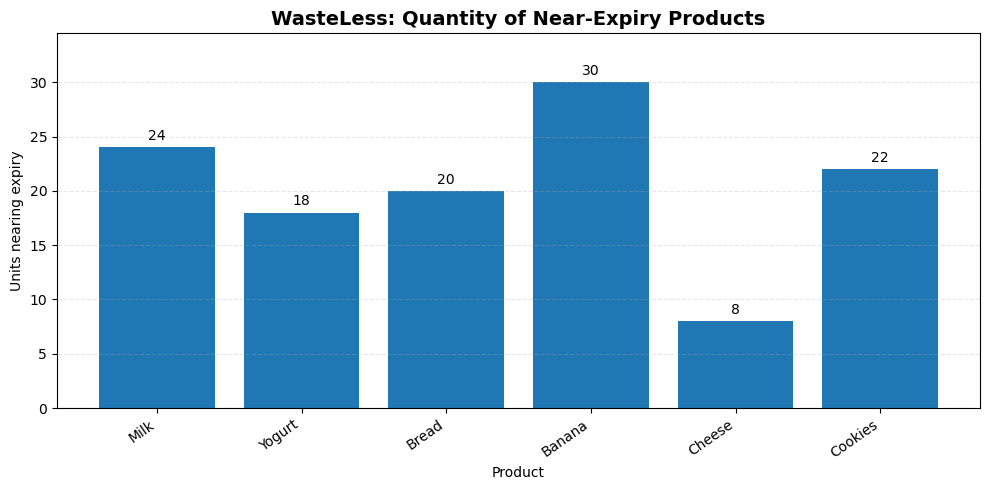

In [29]:

import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)



near_expiry = inventory[inventory["Near_Expiry"]].copy()

if near_expiry.empty:
    print("No products are currently nearing expiry.")
else:
    products = near_expiry["Product"].astype(str).tolist()
    quantities = near_expiry["Quantity"].astype(int).tolist()

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(products, quantities)

    ax.set_title(
        "WasteLess: Quantity of Near-Expiry Products",
        fontsize=14,
        fontweight="bold"
    )
    ax.set_xlabel("Product")
    ax.set_ylabel("Units nearing expiry")

    ax.tick_params(axis="x", labelrotation=35)
    plt.setp(ax.get_xticklabels(), ha="right")

    # Display quantity above each bar
    ax.bar_label(bars, padding=3)

    ax.set_ylim(0, max(quantities) * 1.15)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


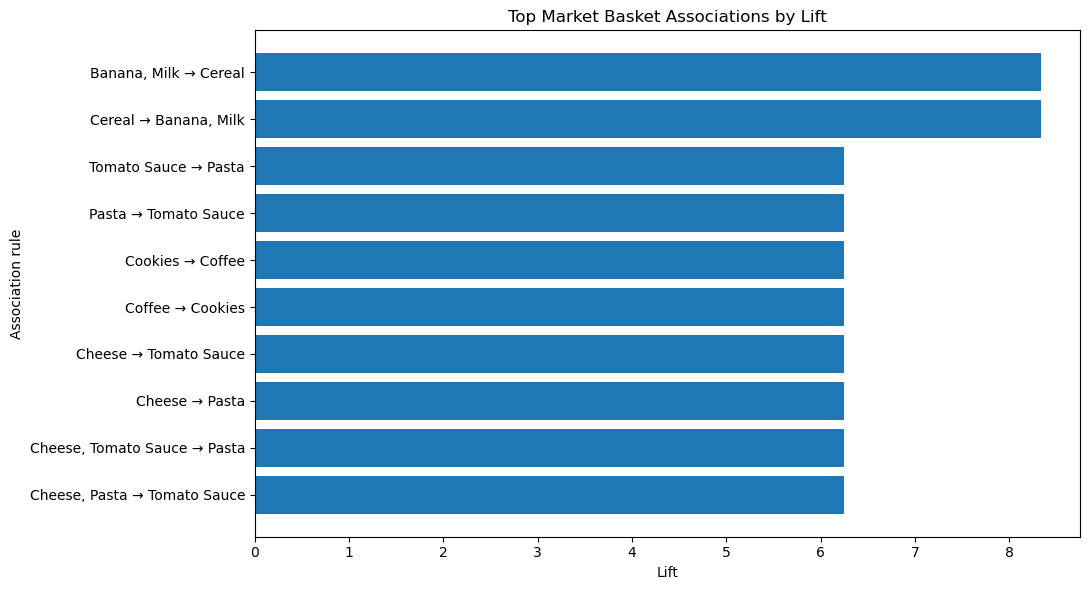

In [30]:

if not rules.empty:

    top_rules = rules.head(10).copy()

    top_rules["Rule"] = (
        top_rules["Antecedents"]
        + " → "
        + top_rules["Consequents"]
    )

    plt.figure(figsize=(11, 6))

    plt.barh(
        top_rules["Rule"],
        top_rules["lift"]
    )

    plt.title("Top Market Basket Associations by Lift")
    plt.xlabel("Lift")
    plt.ylabel("Association rule")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No rules available to visualize.")


In [31]:

total_products = len(inventory)
near_expiry_count = int(inventory["Near_Expiry"].sum())

units_at_risk = int(
    inventory.loc[inventory["Near_Expiry"], "Quantity"].sum()
)

total_transactions = len(transactions)
total_rules = len(rules)

display(Markdown(f"""
# 🌱 WasteLess Dashboard

| Metric | Result |
|---|---:|
| Transactions analyzed | {total_transactions} |
| Products monitored | {total_products} |
| Products nearing expiry | {near_expiry_count} |
| Units in near-expiry inventory | {units_at_risk} |
| Association rules discovered | {total_rules} |
| Promotional offers generated | {len(offers_df)} |

**Goal:** Use purchase patterns to design relevant promotions for products
approaching expiry and help reduce avoidable food waste.
"""))



# 🌱 WasteLess Dashboard

| Metric | Result |
|---|---:|
| Transactions analyzed | 25 |
| Products monitored | 15 |
| Products nearing expiry | 6 |
| Units in near-expiry inventory | 122 |
| Association rules discovered | 59 |
| Promotional offers generated | 6 |

**Goal:** Use purchase patterns to design relevant promotions for products
approaching expiry and help reduce avoidable food waste.


In [34]:
# Export frequent itemsets if defined
if "frequent_itemsets" in globals() and not frequent_itemsets.empty:
    frequent_export = frequent_itemsets.copy()
    frequent_export["itemsets"] = frequent_export["itemsets"].apply(
        lambda x: ", ".join(sorted(x))
    )
    frequent_export.to_csv("WasteLess_Frequent_Itemsets.csv", index=False)
else:
    print("Notice: 'frequent_itemsets' not found or empty. Skipped export.")

# Export inventory and promotions
if "inventory" in globals():
    inventory.to_csv("WasteLess_Inventory.csv", index=False)

if "offers_df" in globals():
    offers_df.to_csv("WasteLess_Promotional_Offers.csv", index=False)

# Export association rules
if "rules" in globals() and not rules.empty:
    rules_export = rules.copy()
    rules_export["antecedents"] = rules_export["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    rules_export["consequents"] = rules_export["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    rules_export.to_csv("WasteLess_Association_Rules.csv", index=False)
else:
    print("Notice: 'rules' not found or empty. Skipped export.")

print("Export process finished!")

Export process finished!
